In [1]:
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["savefig.dpi"] = 1200
from scipy import stats
from IPython.display import display
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MultipleLocator
from scipy.stats import linregress

RUN_DIR = "results"
FIGURE_CSV_DIR = Path(RUN_DIR).resolve() / "figure_table_csv"
FIGURE_CSV_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_EXT = "png"  
def figure_path(number):
    return FIGURE_CSV_DIR / f"Figure_{number}.{FIGURE_EXT}"
def figure_csv_path(number):
    return FIGURE_CSV_DIR / f"Figure_{number}.csv"
def table_path(number):
    return FIGURE_CSV_DIR / f"Table_{number}.csv"
MAIN_CONDITION = "degradation_degw_1_vdevw_0p2_p_0p8_rho_0p4_CA"
SEEDS = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
MA_W = 5
TH = 0.9
ALGOS = {
    "CAHG-MASAC": ("CAHG-MASAC [Ours]", "sienna", "royalblue", "*"),
    "CA-MASAC": ("CA-MASAC", "green", "darkorange", None),
    "MASAC": ("MASAC", "dimgray", "sienna", None),
    "CAHG-MATD3": ("CAHG-MATD3", "orange", "lightcoral", "*"),
    "CA-MATD3": ("CA-MATD3", "skyblue", "skyblue", None),
    "MATD3": ("MATD3", "orchid", "orchid", None),
}
MODES = {"V2G": (True, "VPP Event Episode", 1), "V2H": (False, "Non VPP Episode", 2)}
def ci95(x):
    x = np.asarray(x, float); n = len(x)
    h = stats.t.ppf(0.975, n - 1) * x.std(ddof=1) / np.sqrt(n)
    return x.mean(), x.mean() - h, x.mean() + h
def load_seed(s):
    for f in sorted(Path(f"{RUN_DIR}/seed{s}").glob(f"all_daily_rewards_seed{s}_c*.csv")):
        if pd.read_csv(f, nrows=1, encoding="utf-8-sig").condition[0] == MAIN_CONDITION:
            df = pd.read_csv(f, encoding="utf-8-sig")
            return df[df.phase == "train"].sort_values("day_idx")
    raise FileNotFoundError(f"seed{s}: {MAIN_CONDITION}")
dfs = [load_seed(s) for s in SEEDS]
R = {mode: {a: np.array([d[(d.algorithm == a) & (d.vpp_request == vpp)].reward.values for d in dfs]) for a in ALGOS} for mode, (vpp, _, _) in MODES.items()}
def show(tab):
    display(tab.style.format(precision=3).set_table_styles([{"selector": "th", "props": [("text-align", "center")]}]).set_properties(**{"text-align": "center"}))
def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); adj = np.empty_like(p); run = 0
    for k, i in enumerate(order):
        run = max(run, (len(p) - k) * p[i]); adj[i] = min(run, 1.0)
    return adj
def wilcoxon_p(x, y):
    return 1.0 if np.allclose(x, y) else stats.wilcoxon(x, y).pvalue
def calculate_t90(X, R0, Rmax):
    if np.isclose(Rmax, R0):
        raise ValueError("Rmax and R0 are equal. T90 normalization is undefined.")
    N = (X - R0) / (Rmax - R0)
    return np.array([np.where(ma >= TH)[0][0] + 1 if np.any(ma >= TH) else np.nan for ma in (pd.Series(n).rolling(MA_W).mean().values for n in N)], dtype=float)
def plot_curve(mode):
    _, xlabel, col = MODES[mode]
    plt.figure(figsize=(6, 5))
    for a, (label, *colors, marker) in ALGOS.items():
        X = R[mode][a]; n = len(X)
        mean = X.mean(0)
        half = stats.t.ppf(0.975, n - 1) * X.std(0, ddof=1) / np.sqrt(n)
        x = np.arange(X.shape[1])
        plt.plot(x, mean, color=colors[col - 1], marker=marker, markersize=6, label=label)
        plt.fill_between(x, mean - half, mean + half, color=colors[col - 1], alpha=0.15, linewidth=0)
    figure_data = {"Episode": np.arange(1, next(iter(R[mode].values())).shape[1] + 1)}
    for algo, X in R[mode].items():
        avg = X.mean(axis=0)
        ci = stats.t.ppf(0.975, len(X)-1) * X.std(axis=0, ddof=1) / np.sqrt(len(X))
        figure_data[f"{algo}_Mean"] = avg
        figure_data[f"{algo}_CI_Lower"] = avg - ci
        figure_data[f"{algo}_CI_Upper"] = avg + ci
    pd.DataFrame(figure_data).to_csv(figure_csv_path(8 if mode == "V2G" else 9), index=False, encoding="utf-8-sig")
    plt.title(f"{mode} Performance Comparison [10 seeds Mean] ± 95% CI", fontweight="bold")
    plt.xlabel(xlabel, fontweight="bold"); plt.ylabel("Reward", fontweight="bold"); plt.grid(True)
    h, l = plt.gca().get_legend_handles_labels()
    order = [0, 3, 1, 4, 2, 5]
    plt.legend([h[i] for i in order], [l[i] for i in order], loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=10)
    plt.tight_layout()
    plt.savefig(figure_path(8 if mode == "V2G" else 9), dpi=1200)
    plt.show()
def show_tables(mode):
    Rmax = max(R[mode][a][:, -30:].mean() for a in ALGOS)
    R0 = np.mean([R[mode][a][:, 0].mean() for a in ALGOS])
    rows = {}
    combined = pd.DataFrame(index=[f"Seed {s}" for s in SEEDS])
    raw = pd.DataFrame(index=[f"Seed {s}" for s in SEEDS])
    mean_row = {}
    for a in ALGOS:
        X = R[mode][a]
        rewards = X[:, -30:].mean(1)
        t90 = calculate_t90(X, R0, Rmax)
        valid = t90[np.isfinite(t90)]
        m30, lo, hi = ci95(rewards)
        N = (X - R0) / (Rmax - R0)
        A = N.mean(1)
        t90_summary = f"{valid.mean():.1f} ± {valid.std(ddof=1):.1f}" if len(valid) > 1 else f"{valid[0]:.0f}" if len(valid) else "NR"
        rows[a] = {
            "Max reward": X.max(1).mean(),
            "Last 30 mean": m30,
            "95% CI (Last 30)": f"[{lo:.3f}, {hi:.3f}]",
            "T90 (seeds reached)": f"{t90_summary} ({len(valid)}/{len(t90)})",
            "AUC": f"{A.mean():.3f} ± {A.std(ddof=1):.3f}"
        }
        combined[a] = [f"{r:.3f} / {int(t)}" if np.isfinite(t) else f"{r:.3f} / NR" for r, t in zip(rewards, t90)]
        mean_row[a] = f"{rewards.mean():.3f} ± {rewards.std(ddof=1):.3f} / {t90_summary} ({len(valid)}/{len(t90)})"
        raw[f"{a}_Reward"] = rewards
        raw[f"{a}_T90"] = t90
    T2 = pd.DataFrame(rows).T
    show(T2)
    T2.to_csv(table_path({"V2G": 8, "V2H": 9}[mode]), encoding="utf-8-sig")
    reward_mean_row = {}
    t90_mean_row = {}
    for a in ALGOS:
        rewards = raw[f"{a}_Reward"].to_numpy(dtype=float)
        t90 = raw[f"{a}_T90"].to_numpy(dtype=float)
        valid = t90[np.isfinite(t90)]
        reward_mean_row[a] = f"{rewards.mean():.3f} ± {rewards.std(ddof=1):.3f}"
        t90_str = f"{valid.mean():.1f} ± {valid.std(ddof=1):.1f}" if len(valid) > 1 else f"{valid[0]:.1f}" if len(valid) == 1 else "NR"
        t90_mean_row[a] = f"{t90_str} ({len(valid)}/{len(t90)})"
    combined.loc["Reward Mean ± SD"] = reward_mean_row
    combined.loc["T90 Mean ± SD"] = t90_mean_row

    show(combined)
    combined.to_csv(
        table_path({"V2G": 2, "V2H": 2_1}[mode]),
        encoding="utf-8-sig"
    )

# Figure 8. V2G(+V2H) Event Reward

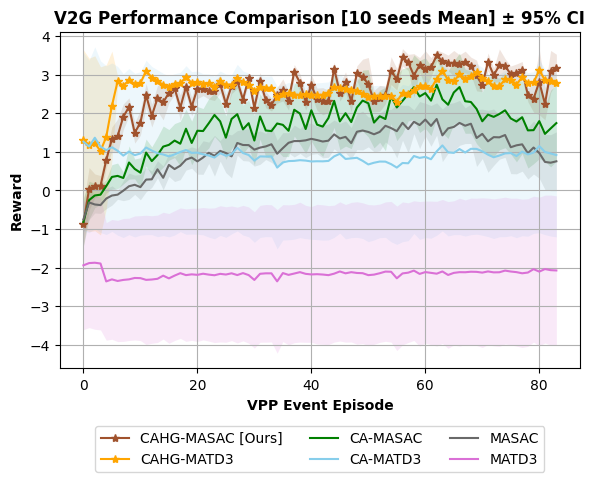

In [2]:
plot_curve("V2G")

# Table 2. V2G(+V2H) Reward Performances

In [3]:
show_tables("V2G")

,Max reward,Last 30 mean,95% CI (Last 30),T90 (seeds reached),AUC
CAHG-MASAC,3.787,3.077,"[2.977, 3.177]",34.3 ± 11.2 (10/10),0.834 ± 0.022
CA-MASAC,3.133,2.118,"[1.315, 2.921]",52.4 ± 8.6 (7/10),0.571 ± 0.238
MASAC,2.143,1.404,"[0.880, 1.927]",NR (0/10),0.394 ± 0.140
CAHG-MATD3,3.367,2.792,"[2.768, 2.816]",7.1 ± 3.2 (10/10),0.864 ± 0.062
CA-MATD3,1.535,0.928,"[-1.197, 3.052]",5.0 ± 0.0 (7/10),0.359 ± 0.873
MATD3,-1.399,-2.121,"[-4.009, -0.233]",56.0 ± 9.9 (2/10),-0.550 ± 0.732


,CAHG-MASAC,CA-MASAC,MASAC,CAHG-MATD3,CA-MATD3,MATD3
Seed 0,3.189 / 41,2.929 / 59,1.289 / NR,2.806 / 6,2.769 / 5,2.865 / 63
Seed 1,3.059 / 28,0.681 / NR,1.151 / NR,2.776 / 12,-3.378 / NR,-3.378 / NR
Seed 2,2.826 / 29,0.637 / NR,2.209 / NR,2.846 / 12,-3.384 / NR,-3.384 / NR
Seed 3,3.286 / 21,3.426 / 36,1.928 / NR,2.793 / 5,-3.365 / NR,-3.365 / NR
Seed 4,3.119 / 49,3.175 / 55,1.408 / NR,2.801 / 5,2.791 / 5,2.909 / 49
Seed 5,2.974 / 18,3.293 / 49,2.058 / NR,2.794 / 5,2.790 / 5,-3.408 / NR
Seed 6,2.971 / 49,2.585 / 60,1.857 / NR,2.809 / 5,2.795 / 5,-3.362 / NR
Seed 7,2.982 / 42,1.847 / 59,-0.082 / NR,2.714 / 11,2.710 / 5,-3.342 / NR
Seed 8,3.148 / 39,0.758 / NR,1.743 / NR,2.793 / 5,2.802 / 5,-3.378 / NR
Seed 9,3.216 / 27,1.848 / 49,0.475 / NR,2.786 / 5,2.748 / 5,-3.367 / NR


# Table 3. Statistical Comparison

In [4]:
for mode in ["V2G"]:
    reference = R[mode]["CAHG-MASAC"][:, -30:].mean(axis=1)
    results = []
    for algo in ALGOS:
        if algo == "CAHG-MASAC":
            continue
        baseline = R[mode][algo][:, -30:].mean(axis=1)
        differences = reference - baseline
        p_value = stats.wilcoxon(
            differences,
            alternative="two-sided",
            method="auto"
        ).pvalue
        results.append({
            "Baseline": algo,
            "Mean reward difference": differences.mean(),
            "Wilcoxon p-value": p_value
        })
    T3 = pd.DataFrame(results)
    T3["Holm-adjusted p-value"] = holm(
        T3["Wilcoxon p-value"].to_numpy()
    )
    display(
        T3.style
        .hide(axis="index")
        .format({
            "Mean reward difference": "{:.3f}",
            "Wilcoxon p-value": "{:.4f}",
            "Holm-adjusted p-value": "{:.4f}"
        })
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "center")]},
            {"selector": "td", "props": [("text-align", "center")]}
        ])
    )
    T3.to_csv(
        table_path({"V2G": 3, "V2H": 3_1}[mode]),
        index=False,
        encoding="utf-8-sig"
    )


Baseline,Mean reward difference,Wilcoxon p-value,Holm-adjusted p-value
CA-MASAC,0.959,0.0371,0.0371
MASAC,1.673,0.0020,0.0098
CAHG-MATD3,0.285,0.0039,0.0098
CA-MATD3,2.149,0.0020,0.0098
MATD3,5.198,0.0020,0.0098


# Figure 9. V2H Event Reward

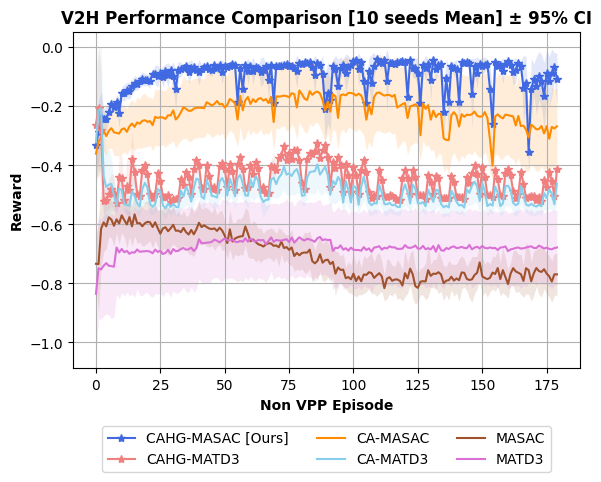

In [5]:
plot_curve("V2H")

# Table 4. Peak Charging Reduction

In [6]:
RUNS = [Path(RUN_DIR)]
OUT = FIGURE_CSV_DIR                  
WARMUP, H = 66, 5                     
ROWS = {"No V2H & V2G": "t2_noV2X",
        "CAHG-MASAC": "t2_ours400"}
FILE_NAME = {"No V2H & V2G": "Table4_noV2H_V2G.csv",
             "CAHG-MASAC": "Table4_CAHG-MASAC.csv"}
STAGES = ["Early training", "Middle training", "Late training", "Evaluation"]
is_true = lambda s: s.astype(str).str.lower().isin(["true", "1", "1.0"])
a = pd.concat([pd.read_csv(f, encoding="utf-8-sig")
               for R_ in RUNS for f in R_.glob("seed*/all_daily_action_counts*.csv")],
              ignore_index=True)
a = a[(a.algo == "hsac") & is_true(a.vpp_req) & a.sweep_type.isin(ROWS.values())].copy()
a["per_hour"] = a.n_Charging / H
train_days = sorted(a[(a.sweep_type == "t2_ours400") & (a.stat == "train")
                      & (a.day_idx >= WARMUP)].day_idx.unique())
split = np.array_split(train_days, 3)
stage_of = {d: STAGES[i] for i, dd in enumerate(split) for d in dd}
a["stage"] = np.where(a.stat == "eval", "Evaluation", a.day_idx.map(stage_of))
a = a.dropna(subset=["stage"])
for label, sw in ROWS.items():
    wide = (a[a.sweep_type == sw]
            .pivot_table(index="seed", columns=["stage", "day_idx"], values="per_hour")
            .reindex(columns=STAGES, level="stage").round(2))
    wide.index.name = "seed"
    #wide.to_csv(table_path({"No V2H & V2G": 16, "CAHG-MASAC": 17}[label]), encoding="utf-8-sig")
fmt = lambda s: "--" if s.empty else (f"{s.mean():.2f} ± {s.std(ddof=1):.2f}" if len(s) > 1 else f"{s.mean():.2f}")
T4, ndays = {}, {}
for label, sw in ROWS.items():
    daily = a[a.sweep_type == sw].groupby(["stage", "day_idx"]).per_hour.mean()
    lv = daily.index.get_level_values(0)
    T4[label] = {st: fmt(daily.loc[st]) if st in lv else "--" for st in STAGES}
    for st in STAGES:
        if st in lv:
            ndays[st] = len(daily.loc[st])
T4 = pd.DataFrame(T4).T[STAGES]
T4.loc["V2G event days"] = [f"{ndays.get(st, 0)} days" for st in STAGES]
T4 = T4.loc[["V2G event days"] + list(ROWS)]
T4.index.name = "Period"
display(T4)
T4.to_csv(table_path(4), encoding="utf-8-sig")

,Early training,Middle training,Late training,Evaluation
Period,,,,
V2G event days,28 days,28 days,28 days,9 days
No V2H & V2G,30.46 ± 13.21,25.07 ± 3.15,25.97 ± 5.86,40.18 ± 3.38
CAHG-MASAC,20.70 ± 17.41,8.25 ± 2.01,6.92 ± 2.55,0.00 ± 0.00


# Table 5. Grid Stability Analysis 

In [7]:
STUDIES = [
    ("t2_noV2X", "(i) No V2H & V2G"),
    ("t2_nopen", "(ii) Without penalty"),
    ("t2_ours400", "(iii) CAHG-MASAC (Ours)"),
    ("t2_ours500", "(iv) CAHG-MASAC (Ours)")
]
VPP_ONLY = True
V_MIN, V_MAX = 0.95, 1.05
ALGO_KEY = "hsac"
def load_csv_group(token):
    files = sorted(Path(RUN_DIR).glob(f"seed*/all_{token}*.csv"))
    df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    df = df[df["sweep_type"].str.startswith("t2_")].copy()
    if "algo" in df.columns:
        df = df[df["algo"].str.lower() == ALGO_KEY].copy()
    else:
        df = df[df["algorithm"] == "CAHG-MASAC"].copy()
    return df
daily = load_csv_group("daily_rewards")
grid = load_csv_group("grid_steps")
daily = daily.drop_duplicates(["sweep_type", "seed", "day_idx"], keep="last").copy()
grid = grid.drop_duplicates(["sweep_type", "seed", "t_idx"], keep="last").copy()
for df in (daily, grid):
    df["seed"] = pd.to_numeric(df["seed"]).astype(int)
    df["day_idx"] = pd.to_numeric(df["day_idx"]).astype(int)
for col in ("vpu_min", "vpu_max", "voltage_deviation"):
    grid[col] = pd.to_numeric(grid[col])
daily = daily[daily["phase"].str.lower() == "eval"].copy()
if VPP_ONLY:
    daily = daily[daily["vpp_request"].astype(str).str.strip().str.lower().isin(["true", "1", "yes"])].copy()
grid_eval = grid.merge(daily[["sweep_type", "seed", "day_idx"]].drop_duplicates(), on=["sweep_type", "seed", "day_idx"], how="inner")
grid_eval["any_violation"] = ((grid_eval["vpu_min"] < V_MIN) | (grid_eval["vpu_max"] > V_MAX)).astype(int)
rows = []
for study, label in STUDIES:
    d = daily[daily["sweep_type"] == study]
    g = grid_eval[grid_eval["sweep_type"] == study]
    eligible = round(float(d["n_evs"].iloc[0]) * float(d["participation_rate"].iloc[0]))
    total_by_seed = g.groupby("seed")["any_violation"].sum()
    min_by_seed = g.groupby("seed")["vpu_min"].min()
    max_by_seed = g.groupby("seed")["vpu_max"].max()
    deviation_by_seed = g.groupby("seed")["voltage_deviation"].mean()
    violation_by_day = g.groupby(["seed", "day_idx"])["any_violation"].max().reset_index()
    days_rate_by_seed = violation_by_day.groupby("seed")["any_violation"].mean() * 100
    rows.append({
        "Category": label,
        "V2G eligible vehicles": eligible,
        "Voltage violations (mean)": round(total_by_seed.mean(), 1),
        "Days with violation (%)": round(days_rate_by_seed.mean(), 2),
        "mean_deviation (p.u.)": round(deviation_by_seed.mean(), 5),
        "Minimum Vpu": round(min_by_seed.min(), 4),
        "Maximum Vpu": round(max_by_seed.max(), 4)
    })
T5 = pd.DataFrame(rows)
display(T5)
FIGURE_CSV_DIR.mkdir(parents=True, exist_ok=True)
T5.to_csv(table_path(5), index=False, encoding="utf-8-sig")

,Category,V2G eligible vehicles,Voltage violations (mean),Days with violation (%),mean_deviation (p.u.),Minimum Vpu,Maximum Vpu
0,(i) No V2H & V2G,400,18.7,47.78,0.01381,0.9495,1.0516
1,(ii) Without penalty,400,0.2,2.22,0.01117,0.9495,1.0453
2,(iii) CAHG-MASAC (Ours),400,0.1,1.11,0.01092,0.9497,1.0453
3,(iv) CAHG-MASAC (Ours),500,0.0,0.00,0.01007,0.9547,1.0447


# Table 6. Performance Analysis for Evaluation Period

In [8]:
files = sorted(Path(RUN_DIR).glob("seed*/all_daily_rewards*.csv"))
df = pd.concat([pd.read_csv(f, encoding="utf-8-sig") for f in files], ignore_index=True)
df = df[(df["condition"] == MAIN_CONDITION) & (df["phase"] == "eval") & (df["algorithm"].isin(ALGOS)) & (df["seed"].isin(SEEDS))].copy()
df = df.drop_duplicates(["condition", "algorithm", "seed", "day_idx", "phase"], keep="last")
df["day_idx"] = pd.to_numeric(df["day_idx"])
df["reward"] = pd.to_numeric(df["reward"])
df["vpp_request"] = df["vpp_request"].astype(str).str.strip().str.lower().isin(["true", "1", "1.0"])
df = df.sort_values("day_idx").groupby(["algorithm", "seed"], group_keys=False).tail(30).copy()
df["Mode"] = np.where(df["vpp_request"], "V2G", "V2H")
rows = {}
for algo in ALGOS:
    rows[algo] = {}
    for mode in ["V2G", "V2H"]:
        q = df[(df["algorithm"] == algo) & (df["Mode"] == mode)]
        seed_means = q.groupby("seed")["reward"].mean()
        rows[algo][(mode, "Mean ± SD")] = f"{seed_means.mean():.3f} ± {seed_means.std(ddof=1):.3f}"
        rows[algo][(mode, "Max / Min")] = f"{seed_means.max():.3f} / {seed_means.min():.3f}"
T6 = pd.DataFrame.from_dict(rows, orient="index")
T6 = T6.reindex(columns=pd.MultiIndex.from_product([["V2G", "V2H"], ["Mean ± SD", "Max / Min"]]))
T6.index = ["CAHG-MASAC (Ours)" if a == "CAHG-MASAC" else a for a in T6.index]
T6.index.name = "Algorithm"
display(T6)
T6.to_csv(table_path(6), encoding="utf-8-sig")

V2G                             V2H  \
                        Mean ± SD       Max / Min       Mean ± SD   
Algorithm                                                           
CAHG-MASAC (Ours)   3.178 ± 0.236   3.252 / 2.505  -0.177 ± 0.013   
CA-MASAC            1.628 ± 2.243  3.253 / -2.874  -0.197 ± 0.104   
MASAC               1.782 ± 0.706  2.006 / -0.226  -0.707 ± 0.189   
CAHG-MATD3          2.196 ± 0.000   2.196 / 2.196  -0.422 ± 0.000   
CA-MATD3            0.675 ± 2.449  2.196 / -2.874  -0.441 ± 0.031   
MATD3              -1.898 ± 2.057  2.006 / -2.874  -0.542 ± 0.119   

                                    
                         Max / Min  
Algorithm                           
CAHG-MASAC (Ours)  -0.173 / -0.215  
CA-MASAC           -0.104 / -0.486  
MASAC              -0.169 / -0.767  
CAHG-MATD3         -0.422 / -0.422  
CA-MATD3           -0.422 / -0.486  
MATD3              -0.486 / -0.767

# Figure 10. Voltage Analysis

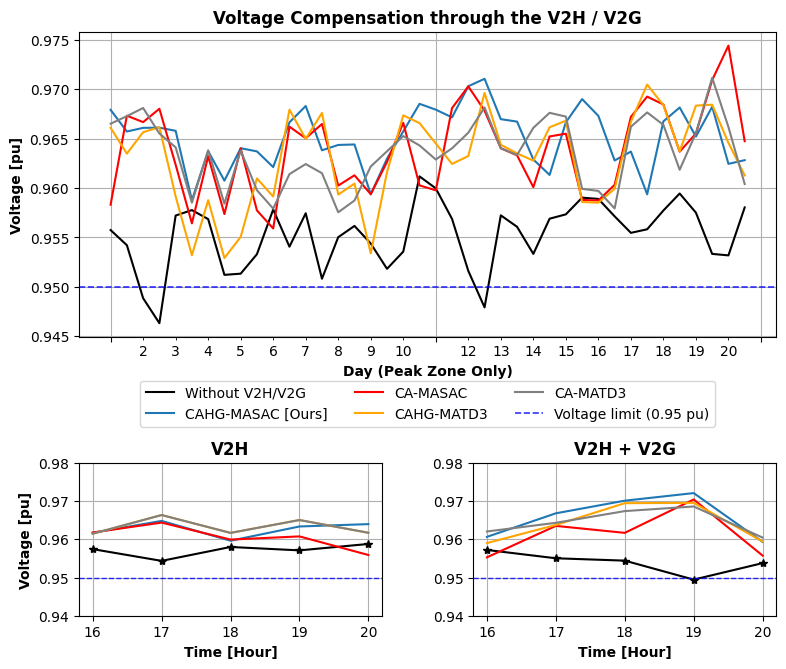

In [9]:
fig = plt.figure(figsize=(9, 8))
gs = GridSpec(2, 2, height_ratios=[2, 1], hspace=0.55)
V_REF = 0.95
vpu_def = pd.read_csv("./results/vpu_def.txt")
vpu_hsac_10 = pd.read_csv("./results/vpu_hsac.txt")
vpu_sac_10 = pd.read_csv("./results/vpu_sac.txt")
vpu_htd_10 = pd.read_csv("./results/vpu_htd.txt")
vpu_td_10 = pd.read_csv("./results/vpu_td.txt")
ax_top = fig.add_subplot(gs[0, :])
x_ticks = np.arange(0, 40, 2)
labels = np.arange(1, len(x_ticks)+1)
x = np.arange(40)
ax_top.plot(x, vpu_def[200:240], color='black', label='Without V2H/V2G')
ax_top.plot(x, vpu_hsac_10[200:240], label='CAHG-MASAC [Ours]')
ax_top.plot(x, vpu_sac_10[200:240], color='red', label='CA-MASAC')
ax_top.plot(x, vpu_htd_10[200:240], color='orange', label='CAHG-MATD3')
ax_top.plot(x, vpu_td_10[200:240], color='gray', label='CA-MATD3')
ax_top.axhline(
    y=V_REF,
    color='blue',
    linestyle='--',
    linewidth=1.2,
    alpha=0.8,
    label='Voltage limit (0.95 pu)'
)
ax_top.set_title("Voltage Compensation through the V2H / V2G", fontweight="bold")
ax_top.set_xlabel("Day (Peak Zone Only)", fontweight="bold")
ax_top.xaxis.set_major_locator(MultipleLocator(20))
ax_top.xaxis.set_minor_locator(MultipleLocator(20))
ax_top.set_xticks(x_ticks, minor=True)
ax_top.set_xticklabels(labels, minor=True)
ax_top.tick_params(axis='x', which='major', labelbottom=False)
ax_top.set_ylabel("Voltage [pu]", fontweight="bold")
ax_top.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=True,
    fontsize=10
)
ax_top.grid(True)
axs = [
    fig.add_subplot(gs[1, 0]),
    fig.add_subplot(gs[1, 1]),
]
y_min, y_max = 0.940, 0.980
x_zoom = np.arange(16, 21)
axs[0].plot(x_zoom, vpu_def[420:425], color='black', marker='*')
axs[0].plot(x_zoom, vpu_hsac_10[420:425])
axs[0].plot(x_zoom, vpu_sac_10[420:425], color='red')
axs[0].plot(x_zoom, vpu_htd_10[420:425], color='orange')
axs[0].plot(x_zoom, vpu_htd_10[420:425], color='gray')
axs[0].set_title('V2H', fontsize=12, fontweight="bold")
axs[0].set_ylim(y_min, y_max)
axs[0].grid(True)
axs[1].plot(x_zoom, vpu_def[245+180:250+180], color='black', marker='*')
axs[1].plot(x_zoom, vpu_hsac_10[245+180:250+180])
axs[1].plot(x_zoom, vpu_sac_10[245+180:250+180], color='red')
axs[1].plot(x_zoom, vpu_htd_10[245+180:250+180], color='orange')
axs[1].plot(x_zoom, vpu_td_10[245+180:250+180], color='gray')
axs[1].set_title('V2H + V2G', fontsize=12, fontweight="bold")
axs[1].set_ylim(y_min, y_max)
axs[1].grid(True)
for ax in axs:
    ax.axhline(
        y=V_REF,
        color='blue',
        linestyle='--',
        linewidth=1.0,
        alpha=0.8
    )
for ax in axs:
    ax.set_xlabel('Time [Hour]', fontweight="bold")
axs[0].set_ylabel('Voltage [pu]', fontweight="bold")
plt.subplots_adjust(hspace=0.5, wspace=0.3, bottom=0.15)
fig.savefig(figure_path(10), dpi=1200, bbox_inches="tight")
plt.show()
parts = []
for panel, idx, xx in [("Top", slice(200,240), x), ("V2H", slice(420,425), x_zoom), ("V2H_V2G", slice(425,430), x_zoom)]:
    d = pd.DataFrame({"Panel": panel, "X": xx,
        "Without_V2H_V2G": vpu_def.iloc[idx,0].to_numpy(),
        "CAHG_MASAC": vpu_hsac_10.iloc[idx,0].to_numpy(),
        "CA_MASAC": vpu_sac_10.iloc[idx,0].to_numpy(),
        "CAHG_MATD3": vpu_htd_10.iloc[idx,0].to_numpy(),
        "CA_MATD3": vpu_td_10.iloc[idx,0].to_numpy(), "Voltage_limit": V_REF})
    parts.append(d)
pd.concat(parts, ignore_index=True).to_csv(figure_csv_path(10), index=False, encoding="utf-8-sig")


# Figure 11. BCA Analysis

DF > 1 비율: 0.0606


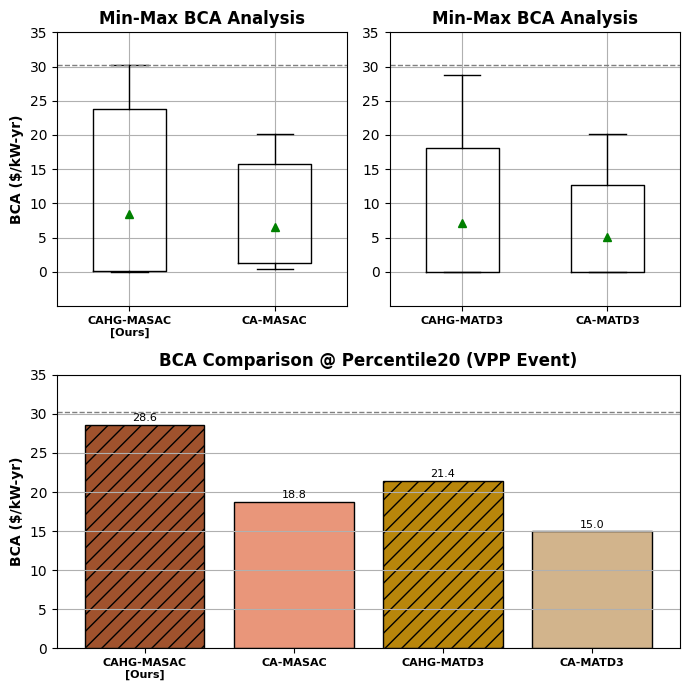

In [10]:
files = sorted(Path(RUN_DIR).glob("seed*/all_daily_rewards*.csv"))
BCA_LOSS, BCA_DCF, BCA_MDC = 0.0728, 1.0, 28.0
P_RATED_KW, PEAK_HOURS = 7.0, 5
BCA_MAX = BCA_MDC * BCA_DCF / (1 - BCA_LOSS)          
D = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
if "sweep_type" in D.columns: D = D[D["sweep_type"] != "scaling"].copy()
D = D[(D["condition"] == MAIN_CONDITION) & (D["phase"] == "eval")].copy()
D = D.drop_duplicates(["condition", "algorithm", "seed", "day_idx"], keep="last")
D["name"] = D["algorithm"].replace({"CAHG-MASAC": "CAHG-MASAC [Ours]"})
D["vpp_request"] = D["vpp_request"].astype(str).str.strip().str.lower().isin(["true", "1", "1.0"])
D["E_kWh"]    = D["V2H_kWh"] + D["V2G_kWh"]
D["P_red_kW"] = D["E_kWh"] / PEAK_HOURS
D["DF_raw"]   = D["P_red_kW"] / (D["n_participants"].replace(0, np.nan) * P_RATED_KW)
print("DF > 1 비율:", (D["DF_raw"] > 1).mean().round(4))   
D["DF"]  = D["DF_raw"].clip(lower=0, upper=1.0)
D["BCA"] = BCA_MDC * BCA_DCF * D["DF"] / (1 - BCA_LOSS)
BCA_ALGOS = ["CAHG-MASAC [Ours]", "CA-MASAC", "CAHG-MATD3", "CA-MATD3"]
BCA_DAY = {n: D[D["name"] == n].groupby("day_idx")["BCA"].mean().dropna() for n in BCA_ALGOS}
BCA_REQUEST = {n: D[(D["name"] == n) & D["vpp_request"]].groupby("day_idx")["BCA"].mean().dropna() for n in BCA_ALGOS}
fig = plt.figure(figsize=(7, 7))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1])
lower, upper, step = 0, 35, 5                          
for k, pair in enumerate((BCA_ALGOS[:2], BCA_ALGOS[2:])):
    ax = fig.add_subplot(gs[0, k])
    ax.boxplot([BCA_DAY[n].to_numpy() for n in pair], whis=(0, 100), showmeans=True, widths=0.5,
               meanprops=dict(marker="^", markerfacecolor="green", markeredgecolor="green"),
               medianprops=dict(color="none"))
    ax.axhline(BCA_MAX, ls="--", lw=1, color="gray")   
    ax.set_xticks([1, 2], [n.replace(" [Ours]", "\n[Ours]") for n in pair], fontsize=8, fontweight="bold")
    ax.set_title("Min-Max BCA Analysis", fontweight="bold")
    ax.set_ylabel("BCA ($/kW-yr)" if k == 0 else "", fontweight="bold")
    ax.set_ylim(-5, upper)                       
    ax.set_yticks(np.arange(0, upper + 1, step)) 
    ax.grid(True)
ax = fig.add_subplot(gs[1, :])
p20 = [np.percentile(BCA_REQUEST[n], 20) for n in BCA_ALGOS]
bars = ax.bar(range(4), p20, color=["#a0522d", "#e9967a", "#b8860b", "#d2b48c"], edgecolor="black")
for i, bar in enumerate(bars):
    if i in (0, 2): bar.set_hatch("//")
for bar, v in zip(bars, p20):                          
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.5, f"{v:.1f}", ha="center", fontsize=8)
ax.axhline(BCA_MAX, ls="--", lw=1, color="gray")
ax.set_xticks(range(4), [n.replace(" [Ours]", "\n[Ours]") for n in BCA_ALGOS], fontsize=8, fontweight="bold")
ax.set_title("BCA Comparison @ Percentile20 (VPP Event)", fontweight="bold")
ax.set_ylabel("BCA ($/kW-yr)", fontweight="bold")
ax.set_ylim(lower, upper)
ax.grid(True, axis="y")
fig.tight_layout()
fig.savefig(figure_path(11), dpi=1200, bbox_inches="tight")
plt.show()
bca_box = pd.DataFrame(BCA_DAY)
bca_box.index.name = "day_idx"
box_long = bca_box.reset_index().melt(id_vars="day_idx", var_name="Algorithm", value_name="BCA")
box_long["Panel"] = "Boxplot"
p20_df = pd.DataFrame({"Panel": "P20", "Algorithm": BCA_ALGOS, "BCA_P20_USD_per_kW_yr": p20})
pd.concat([box_long, p20_df], ignore_index=True).to_csv(figure_csv_path(11), index=False, encoding="utf-8-sig")


# Table 7, 8, 9, 10. Sensitive Studies

In [11]:
T95_WINDOW = 5
T95_THRESHOLD = 0.95
T95_SMOOTH_WINDOW = 10
files = sorted(Path(RUN_DIR).glob("seed*/all_daily_rewards*.csv"))
if not files: raise FileNotFoundError(f"No CSV files found in {RUN_DIR}")
S = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
S = S.drop_duplicates(["condition", "algorithm", "seed", "day_idx", "phase"], keep="last")
S = S[S["sweep_type"].isin(["w3", "participation", "rho", "tariff"])].copy()
S = S[(S["algorithm"] == "CAHG-MASAC") & (S["vpp_request"].astype(str).str.strip().str.lower().isin(["true", "1", "1.0"]))].copy()
S["day_idx"] = pd.to_numeric(S["day_idx"], errors="coerce")
S["reward"] = pd.to_numeric(S["reward"], errors="coerce")
def sustained_t95_event(rewards):
    y = pd.Series(np.asarray(rewards, dtype=float))
    if len(y) < T95_SMOOTH_WINDOW + T95_WINDOW - 1: return np.nan
    smooth = y.rolling(T95_SMOOTH_WINDOW, min_periods=T95_SMOOTH_WINDOW).mean().to_numpy()
    if not np.isfinite(smooth).any(): return np.nan
    target = T95_THRESHOLD * np.nanmax(smooth)
    for start in range(len(smooth) - T95_WINDOW + 1):
        segment = smooth[start:start + T95_WINDOW]
        if np.isfinite(segment).all() and np.all(segment >= target): return float(start + 1)
    return np.nan
def study_table(study, col, values, labels, title):
    data = S[(S["sweep_type"] == study) & (S["phase"] == "train")]
    result = {}
    for value, label in zip(values, labels):
        q = data[np.isclose(pd.to_numeric(data[col], errors="coerce"), value)] if col != "tariff" else data[data[col] == value]
        if q.empty: continue
        daily = q.groupby("day_idx")["reward"].mean().sort_index()
        last30_reward = daily.tail(30).mean()
        per_seed_t95 = []
        for seed, group in q.groupby("seed"):
            seed_daily = group.groupby("day_idx")["reward"].mean().sort_index()
            per_seed_t95.append(sustained_t95_event(seed_daily.to_numpy()))
        valid = np.asarray(per_seed_t95, dtype=float)
        valid = valid[np.isfinite(valid)]
        result[label] = {"Training Reward (Last 30)": round(last30_reward, 3), "Sustained T95 median (per seeds)": float(np.median(valid)) if len(valid) else np.nan}
    table = pd.DataFrame(result)
    table.columns.name = title
    display(table)
    return table
T7 = study_table("w3", "vdev_weight", [0.2, 0.5, 1.0, 1.5, 2.0], ["0.2", "0.5", "1", "1.5", "2"], "Voltage deviation weighting [w3]")
T8 = study_table("participation", "participation_rate", [1.0, 0.8, 0.5, 0.3], ["100%", "80%", "50%", "30%"], "V2G eligible rate")
T9 = study_table("rho", "rho", [0.0, 0.2, 0.4, 0.8, 1.0], ["0.0", "0.2", "0.4", "0.8", "1.0"], "Buffer mixing ratio [ρ]")
T10 = study_table("tariff", "tariff", ["CA", "TX"], ["TOU [California]", "Flat [Texas]"], "Electricity rate")
FIGURE_CSV_DIR.mkdir(parents=True, exist_ok=True)
T7.to_csv(table_path(7), encoding="utf-8-sig")
T8.to_csv(table_path(8), encoding="utf-8-sig")
T9.to_csv(table_path(9), encoding="utf-8-sig")
T10.to_csv(table_path(10), encoding="utf-8-sig")

Voltage deviation weighting [w3],0.2,0.5,1,1.5,2
Training Reward (Last 30),3.077,3.06,2.958,2.888,2.913
Sustained T95 median (per seeds),65.000,63.00,65.000,64.000,64.000


V2G eligible rate,100%,80%,50%,30%
Training Reward (Last 30),3.636,3.077,2.051,1.262
Sustained T95 median (per seeds),66.000,65.000,63.000,64.000


Buffer mixing ratio [ρ],0.0,0.2,0.4,0.8,1.0
Training Reward (Last 30),2.225,3.012,3.077,2.995,2.748
Sustained T95 median (per seeds),66.000,64.000,65.000,63.500,71.000


Electricity rate,TOU [California],Flat [Texas]
Training Reward (Last 30),3.077,3.731
Sustained T95 median (per seeds),65.000,63.000


# Table 9 [Supplemental]. Learning Curve

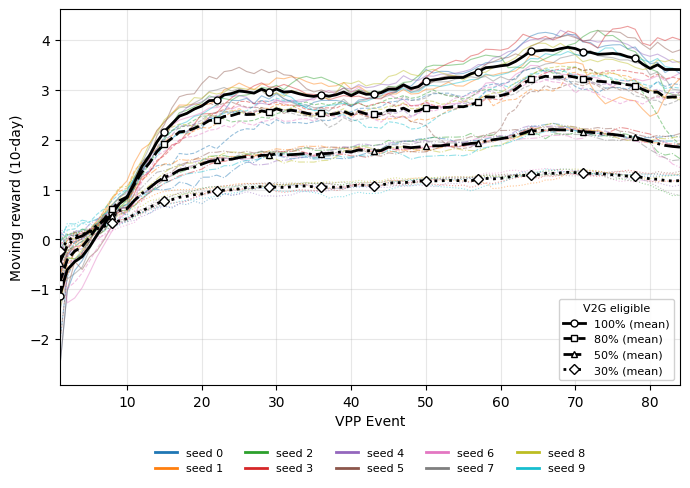

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
PART_VALUES = [1.0, 0.8, 0.5, 0.3]
PART_LABELS = ["100%", "80%", "50%", "30%"]
data = S[(S["sweep_type"] == "participation") & (S["phase"] == "train")].copy()
data["participation_rate"] = pd.to_numeric(data["participation_rate"], errors="coerce")
curves = {}
for value, label in zip(PART_VALUES, PART_LABELS):
    q = data[np.isclose(data["participation_rate"], value)]
    for seed, g in q.groupby("seed"):
        curves[(label, seed)] = g.groupby("day_idx")["reward"].mean().sort_index()
colors  = plt.cm.tab10.colors
styles  = {"100%": "-",  "80%": "--", "50%": "-.", "30%": ":"}
markers = {"100%": "o",  "80%": "s",  "50%": "^",  "30%": "D"}
seeds   = sorted({k[1] for k in curves})
seed_color = {s: colors[i % 10] for i, s in enumerate(seeds)}
fig, ax = plt.subplots(figsize=(7, 5))
plot_cols = {}   
for label in PART_LABELS:
    series = []
    for k in [k for k in curves if k[0] == label]:
        d = curves[k].reset_index(drop=True); d.index = d.index + 1   
        series.append(d)
        sm = d.rolling(T95_SMOOTH_WINDOW, min_periods=1).mean()
        ax.plot(sm.index, sm.values, color=seed_color[k[1]], ls=styles[label], lw=0.8, alpha=0.45)
        plot_cols[f"{label}_seed{k[1]}"] = sm
    if series:
        m = pd.concat(series, axis=1).mean(axis=1).rolling(T95_SMOOTH_WINDOW, min_periods=1).mean()
        ax.plot(m.index, m.values, color="k", ls=styles[label], lw=2,
                marker=markers[label], markevery=7, ms=5, mfc="white", mec="k", zorder=5)
        plot_cols[f"{label}_mean"] = m
ax.set_xlim(1, 84)
ax.set_xlabel("VPP Event")
ax.set_ylabel(f"Moving reward ({T95_SMOOTH_WINDOW}-day)")
ax.grid(alpha=0.3)
rate_handles = [Line2D([], [], color="k", ls=styles[l], lw=2, marker=markers[l],
                       ms=5, mfc="white", mec="k", label=f"{l} (mean)") for l in PART_LABELS]
leg_rate = ax.legend(handles=rate_handles, title="V2G eligible", loc="lower right",
                     fontsize=8, title_fontsize=8, framealpha=0.9)
ax.add_artist(leg_rate)
seed_handles = [Line2D([], [], color=seed_color[s], lw=2, label=f"seed {s}") for s in seeds]
ax.legend(handles=seed_handles, loc="upper center", bbox_to_anchor=(0.5, -0.14),
          ncol=min(len(seeds), 5), fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(figure_path(91), bbox_inches="tight")
fig_df = pd.DataFrame(plot_cols)
fig_df.index.name = "VPP_event"
fig_df.to_csv(figure_csv_path((91)), encoding="utf-8-sig")
plt.show()

# Table 11. Battery Degration Impact Analysis

In [13]:
LAMBDAS = [0.0, 1.0, 2.0, 5.0]
HL = ["V2H_kWh", "V2G_kWh", "V2X_kWh", "charge_kWh", "soc_arr_led", "soc_end_led", "dsoc_led", "reward_final", "degradation_cost", "degradation_penalty_applied"]
REN = {"V2X_kWh": "V2H+V2G_kWh", "soc_arr_led": "soc_arr_led (%)", "soc_end_led": "soc_end_led (%)", "dsoc_led": "ΔSOC = end − arr (%p)"}
GROUP = {**dict.fromkeys(HL[:4], "Energy"), **dict.fromkeys(HL[4:7], "SOC Trajectory"), **dict.fromkeys(HL[7:], "Reward/Cost")}
COLS = ["seed", "deg_weight", "phase", "day_idx", "ev_id", "participant", "V2H_kWh", "V2G_kWh", "charge_kWh", "soc_arr_led", "soc_end_led", "reward_final", "degradation_cost", "degradation_penalty_applied"]
files = sorted(Path(RUN_DIR).glob("seed*/energy_trace_daily_ev_hsac_seed*_c*.csv.gz"))

parts = []

for f in files:
    df = pd.read_csv(f, usecols=COLS)
    df["deg_weight"] = pd.to_numeric(df["deg_weight"], errors="coerce")
    df = df[np.isclose(df["deg_weight"].to_numpy()[:, None], LAMBDAS).any(axis=1)]
    if not df.empty: parts.append(df)

D = pd.concat(parts, ignore_index=True)
D = D.drop_duplicates(["deg_weight", "seed", "phase", "day_idx", "ev_id"], keep="last")
D["participant"] = D["participant"].astype(str).str.strip().str.lower().isin(["true", "1", "1.0"])

PAIRED = sorted(set.intersection(*(set(D.loc[np.isclose(D["deg_weight"], lam), "seed"]) for lam in LAMBDAS)))

E = D[(D["phase"] == "eval") & D["participant"] & D["seed"].isin(PAIRED)].copy()
E["V2X_kWh"] = E["V2H_kWh"] + E["V2G_kWh"]
E[["soc_arr_led", "soc_end_led"]] *= 100
E["dsoc_led"] = E["soc_end_led"] - E["soc_arr_led"]

SM = E.groupby(["deg_weight", "seed"], observed=True)[HL].mean().reset_index()

rows = []
for metric in HL:
    row = {"category": GROUP[metric], "metric": REN.get(metric, metric)}
    for lam in LAMBDAS:
        values = SM.loc[np.isclose(SM["deg_weight"], lam), metric]
        row[f"λ={lam:g}"] = f"{values.mean():.3f} ± {values.std(ddof=1):.3f}"
    rows.append(row)

T11 = pd.DataFrame(rows).set_index(["category", "metric"])
display(T11)
T11.to_csv(table_path(11), encoding="utf-8-sig")

λ=0              λ=1  \
category       metric                                                          
Energy         V2H_kWh                        4.747 ± 4.079    4.767 ± 4.050   
               V2G_kWh                        8.131 ± 2.827    8.123 ± 2.710   
               V2H+V2G_kWh                   12.878 ± 1.327   12.890 ± 1.452   
               charge_kWh                     0.000 ± 0.000    0.000 ± 0.000   
SOC Trajectory soc_arr_led (%)              41.456 ± 10.140  41.489 ± 10.163   
               soc_end_led (%)               22.962 ± 8.410   22.976 ± 8.307   
               ΔSOC = end − arr (%p)        -18.494 ± 1.945  -18.513 ± 2.126   
Reward/Cost    reward_final                   1.320 ± 0.520    1.305 ± 0.504   
               degradation_cost               0.171 ± 0.056    0.171 ± 0.055   
               degradation_penalty_applied    0.000 ± 0.000    0.171 ± 0.055   

                                                        λ=2              λ=5  
category       metric                                                         
Energy         V2H_kWh                        4.836 ± 4.314    4.838 ± 3.756  
               V2G_kWh                        8.078 ± 2.881    7.508 ± 3.489  
               V2H+V2G_kWh                   12.914 ± 1.538   12.347 ± 2.854  
               charge_kWh                     0.000 ± 0.000    0.000 ± 0.000  
SOC Trajectory soc_arr_led (%)               41.408 ± 9.916  32.695 ± 28.883  
               soc_end_led (%)               22.865 ± 7.966  14.964 ± 24.856  
               ΔSOC = end − arr (%p)        -18.544 ± 2.239  -17.731 ± 4.118  
Reward/Cost    reward_final                   1.283 ± 0.529    1.147 ± 0.631  
               degradation_cost               0.170 ± 0.053    0.158 ± 0.055  
               degradation_penalty_applied    0.340 ± 0.106    0.792 ± 0.276

# Figure 12. OpenDSS & GridLAB-D

OpenDSS vs GridLAB-D voltage comparison
Bus/Phase         : 63.1 (A)
MAE               : 0.006193 p.u.


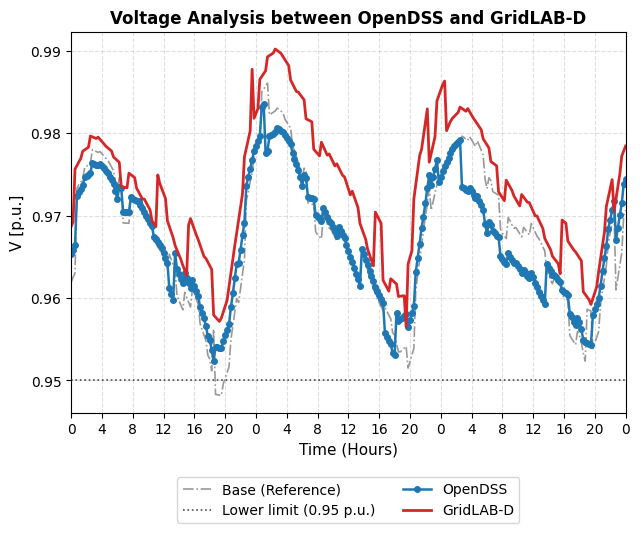

In [14]:
%run "OpenDSS_GridLabD.py"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print("=" * 70)
print("OpenDSS vs GridLAB-D voltage comparison")
print("=" * 70)
print("Bus/Phase         : 63.1 (A)")
print(f"MAE               : {mae:.6f} p.u.")
TICK_INTERVAL = 4
time_array = np.asarray(time_hours, dtype=float)
time_elapsed = time_array - time_array[0]
mask = np.isfinite(time_elapsed) & (time_elapsed >= 0) & (time_elapsed <= 72)
plot_time = time_elapsed[mask]
plot_df = comparison_df.iloc[np.flatnonzero(mask)]
ticks = np.arange(0, 73, TICK_INTERVAL)
F12 = pd.DataFrame({
    "Time_hour": plot_time,
    "Base_Reference_Vpu": plot_df["OpenDSS_S3_Vpu"].to_numpy(),
    "OpenDSS_Vpu": plot_df["OpenDSS_S4_Vpu"].to_numpy(),
    "GridLABD_Vpu": plot_df["GridLABD_S4_Vpu"].to_numpy(),
    "Lower_Limit_Vpu": 0.95
})
F12.to_csv(figure_csv_path(12), index=False, encoding="utf-8-sig")
plt.figure(figsize=(6.5, 5.5))
line_base, = plt.plot(plot_time, plot_df["OpenDSS_S3_Vpu"], label="Base (Reference)", color="gray", linestyle="dashdot", linewidth=1.2, alpha=0.8)
line_opendss, = plt.plot(plot_time, plot_df["OpenDSS_S4_Vpu"], label="OpenDSS", color="#1f77b4", linestyle="-", linewidth=1.8, marker="o", markersize=4)
line_gridlabd, = plt.plot(plot_time, plot_df["GridLABD_S4_Vpu"], label="GridLAB-D", color="#d62728", linestyle="-", linewidth=2)
line_limit = plt.axhline(0.95, color="black", linestyle=":", linewidth=1.2, alpha=0.7, label="Lower limit (0.95 p.u.)")
plt.title("Voltage Analysis between OpenDSS and GridLAB-D", fontsize=12, fontweight="bold")
plt.xlabel("Time (Hours)", fontsize=11)
plt.ylabel("V [p.u.]", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.4)
plt.xticks(ticks, [str(int(t % 24)) for t in ticks], fontsize=10)
plt.xlim(0, 72)
plt.legend([line_base, line_limit, line_opendss, line_gridlabd], ["Base (Reference)", "Lower limit (0.95 p.u.)", "OpenDSS", "GridLAB-D"], loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=10, frameon=True)
plt.tight_layout()
plt.gcf().savefig(figure_path(12), dpi=1200, bbox_inches="tight")
plt.show()


# Table 12, 13. Computation time analysis

In [15]:
files = sorted(Path(RUN_DIR).glob("seed*/all_timing*.csv"))
if not files:
    raise FileNotFoundError("Timing CSV files not found.")
T = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
T = T[T["sweep_type"] == "scaling"].copy()
rows = []
for (condition, algo, seed, n_evs), g in T.groupby(
    ["condition", "algo", "seed", "n_evs"]
):
    g = g.sort_values("day_idx")
    episodes = g[g["phase"].isin(["warmup", "train"])].sort_values("day_idx")
    setup = g.loc[g["phase"] == "setup", "wall_total_s"].sum()
    row = {"Number of EVs": int(n_evs), "algorithm": algo, "seed": seed}
    for n in [100, 200, 300]:
        if len(episodes) >= n:
            part = episodes.head(n)
            total = setup + part["wall_total_s"].sum()
            row[f"{n} episodes"] = total
        else:
            row[f"{n} episodes"] = np.nan
    rows.append(row)
R = pd.DataFrame(rows)
def mean_sd(x):
    x = x.dropna()
    if x.empty:
        return "N/A"
    return f"{x.mean():,.2f} ± {x.std(ddof=1):,.2f}" if len(x) > 1 else f"{x.mean():,.2f}"
metrics = [
    "100 episodes",
    "200 episodes",
    "300 episodes"
]
T12 = R.groupby("Number of EVs")[metrics].agg(mean_sd).T
T12.index = [
    "100 episodes (mean ± SD)",
    "200 episodes (mean ± SD)",
    "300 episodes (mean ± SD)"
]
T12.columns.name = "Number of EVs"
display(T12)
out = FIGURE_CSV_DIR
blocks = [T12.astype(str)]
seed_metrics = [
    "100 episodes",
    "200 episodes",
    "300 episodes"
]
for seed in sorted(R["seed"].unique()):
    S = R[R["seed"] == seed]
    seed_table = S.groupby("Number of EVs")[seed_metrics].mean().T
    seed_table.index = [
        "100 episodes",
        "200 episodes",
        "300 episodes"
    ]
    seed_table = seed_table.reindex(columns=T12.columns)
    seed_table = seed_table.apply(lambda col: col.map(
        lambda x: f"{x:.2f}" if pd.notna(x) else ""
    ))
    title = pd.DataFrame(
        [[""] * len(T12.columns)],
        index=[f"Seed {seed}"],
        columns=T12.columns
    )
    blocks.extend([title, seed_table])
T11_all = pd.concat(blocks)
T11_all.index.name = "Number of EVs"
T11_all.to_csv(table_path(11), encoding="utf-8-sig")

rows = []

for metric in ["100 episodes", "200 episodes", "300 episodes"]:
    # Mean computational time across seeds for each EV fleet size
    M = R.groupby("Number of EVs")[metric].mean().dropna()

    x = M.index.to_numpy(dtype=float)
    y = M.to_numpy(dtype=float)

    reg = linregress(x, y)

    rows.append({
        "Content": metric,
        "Linear Regression Model": f"T(N) = {reg.slope:.5f}N + {reg.intercept:.3f}",
        "R²": f"{reg.rvalue**2:.6f}"
    })

T13 = pd.DataFrame(rows).set_index("Content")

display(T13)

T13.to_csv(table_path(13), encoding="utf-8-sig")

Number of EVs,100,200,300,400,500
100 episodes (mean ± SD),14.44 ± 0.09,17.11 ± 0.10,19.73 ± 0.07,22.35 ± 0.05,25.06 ± 0.05
200 episodes (mean ± SD),22.87 ± 0.14,28.47 ± 0.12,34.02 ± 0.06,39.50 ± 0.10,45.15 ± 0.11
300 episodes (mean ± SD),31.26 ± 0.19,39.71 ± 0.13,48.15 ± 0.07,56.51 ± 0.14,65.05 ± 0.16


,Linear Regression Model,R²
Content,,
100 episodes,T(N) = 0.02647N + 11.799,0.999964
200 episodes,T(N) = 0.05561N + 17.319,0.999981
300 episodes,T(N) = 0.08438N + 22.824,0.999993
